# Part 3: Question 2, EV-Adoption Profiles of Washington ZIP Codes

**Personal project: Electric Vehicle Adoption in Washington State**

**Name:** Bernard Issifu

**Question 2.** What distinct EV-adoption profiles exist across Washington ZIP codes?

Uses the cleaned data from Part 1. The R version is `r/03_q2_clustering.Rmd`.

In [1]:
# ---- Setup ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
FIG_DIR = "../report/figures"
df = pd.read_csv("../data/processed/ev_clean_python.csv", dtype={"zip": str})
print(df.shape)

(299303, 15)


---
# 1. Approach

Question 1 looked at single vehicles. Here each **ZIP code** is the unit, described by its EV fleet, and
**k-means clustering** groups ZIP codes with similar fleets. ZIP codes with fewer than 50 EVs are left
out, because shares computed from a handful of cars are unstable.

**Features per ZIP code** (all standardized to z-scores so each counts equally):

- `log_evs`: log10 of the number of registered EVs (scale of adoption);
- `bev_share`: share that are battery-electric;
- `tesla_share`: share that are Teslas (premium, early-adopter brand);
- `recent_share`: share of model year 2023 or later (how recent the fleet is);
- `brand_entropy`: Shannon entropy of the make distribution (brand diversity).

Median electric range was considered but dropped, because range is recorded as 0 for 66% of vehicles
(Part 1).

**Choosing k.** The elbow method (within-cluster sum of squares) and the average silhouette width are
compared for k = 2 to 8.

In [2]:
def entropy(s):
    p = s.value_counts(normalize=True)
    return float(-(p * np.log(p)).sum())

zips = df.groupby("zip").agg(
    evs=("bev", "size"), bev_share=("bev", "mean"), tesla_share=("tesla", "mean"),
    recent_share=("model_year", lambda s: (s >= 2023).mean()),
    brand_entropy=("Make", entropy),
    region=("region", lambda s: s.mode()[0]), city=("City", lambda s: s.mode()[0]),
    county=("County", lambda s: s.mode()[0]))
print(f"ZIP codes: {len(zips)}; with at least 50 EVs: {(zips['evs'] >= 50).sum()}")
zips = zips[zips["evs"] >= 50].copy()
zips["log_evs"] = np.log10(zips["evs"])
print(f"Share of all EVs covered: {zips['evs'].sum() / len(df):.1%}")

features = ["log_evs", "bev_share", "tesla_share", "recent_share", "brand_entropy"]
zips[features].describe().round(3)

ZIP codes: 590; with at least 50 EVs: 338
Share of all EVs covered: 99.0%


,log_evs,bev_share,tesla_share,recent_share,brand_entropy
count,338.000,338.000,338.000,338.000,338.000
mean,2.676,0.783,0.371,0.601,2.336
std,0.517,0.062,0.100,0.066,0.244
min,1.699,0.415,0.084,0.327,0.925
25%,2.237,0.752,0.296,0.568,2.207
50%,2.737,0.781,0.381,0.601,2.354
75%,3.076,0.818,0.435,0.636,2.498
max,3.852,1.000,0.609,0.901,2.787


In [3]:
zips[features].corr().round(2)

,log_evs,bev_share,tesla_share,recent_share,brand_entropy
log_evs,1.00,0.27,0.27,0.31,0.15
bev_share,0.27,1.00,0.46,0.25,-0.45
tesla_share,0.27,0.46,1.00,0.21,-0.57
recent_share,0.31,0.25,0.21,1.00,-0.29
brand_entropy,0.15,-0.45,-0.57,-0.29,1.00


---
# 2. Choosing the number of clusters

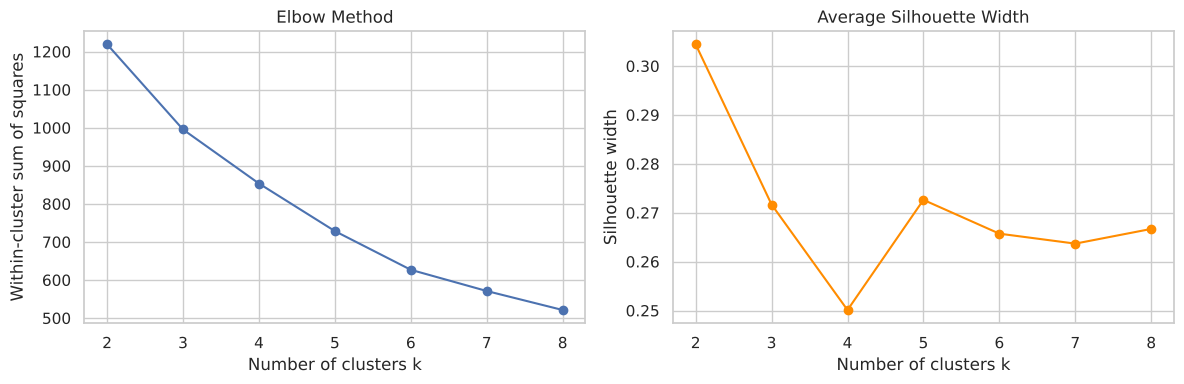

k,2,3,4,5,6,7,8
inertia,1219.267,995.458,853.51,728.480,626.793,571.046,521.137
silhouette,0.304,0.272,0.25,0.273,0.266,0.264,0.267


In [4]:
X = StandardScaler().fit_transform(zips[features])
ks, inertia, sil = range(2, 9), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertia, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Within-cluster sum of squares")
axes[1].plot(list(ks), sil, marker="o", color="darkorange")
axes[1].set_title("Average Silhouette Width")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette width")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q2_choose_k.png", dpi=150)
plt.show()
pd.DataFrame({"k": list(ks), "inertia": inertia, "silhouette": sil}).round(3).set_index("k").T

In [5]:
# k = 5 splits off a tiny group; show its size to justify k = 4
km5 = KMeans(n_clusters=5, n_init=20, random_state=42).fit(X)
print("Cluster sizes with k = 5:", sorted(int(n) for n in np.bincount(km5.labels_)))

Cluster sizes with k = 5: [4, 61, 68, 78, 127]


**Choice of k = 4.** The silhouette is highest at k = 2 (0.304), but two groups only separate "large"
from "small" adoption areas. From k = 3 to 8 the silhouette varies only between 0.250 and 0.273, so it
does not clearly favour any k, and the elbow curve bends gradually. k = 4 has the lowest silhouette in
that range (0.250), but the difference from k = 3 or 5 is small; k = 5 splits off a group of only 4
unusual ZIP codes, and k = 3 folds the PHEV-leaning group found below into the large diverse group. **k = 4** gives
four groups of reasonable size that are easy to interpret, so it is used, accepting a slightly lower
silhouette. The
modest silhouette means the profiles overlap: they are tendencies, not sharply separated types.

---
# 3. The four profiles

In [6]:
km = KMeans(n_clusters=4, n_init=20, random_state=42).fit(X)
zips["cluster"] = km.labels_

prof = zips.groupby("cluster").agg(
    zip_codes=("evs", "size"), median_evs=("evs", "median"), total_evs=("evs", "sum"),
    bev_share=("bev_share", "mean"), tesla_share=("tesla_share", "mean"),
    recent_share=("recent_share", "mean"), brand_entropy=("brand_entropy", "mean"),
    seattle_metro=("region", lambda s: (s == "Seattle metro").mean()),
    eastern_wa=("region", lambda s: (s == "Eastern WA").mean()))

# Name the clusters with simple rules so Python and R label them the same way:
# the two clusters with the most EVs are 'large', the others 'small'.
large = prof["median_evs"].nlargest(2).index
names = {}
names[prof.loc[large, "tesla_share"].idxmax()] = "Tech-suburb Tesla hubs"
names[prof.loc[large, "tesla_share"].idxmin()] = "Diverse urban and suburban"
small = prof.index.difference(large)
names[prof.loc[small, "bev_share"].idxmin()] = "PHEV-leaning mixed fleets"
names[prof.loc[small, "bev_share"].idxmax()] = "Small eastern Tesla-leaning"
zips["profile"] = zips["cluster"].map(names)
prof.index = prof.index.map(names)
prof = prof.sort_values("median_evs", ascending=False)
prof.round(3)

,zip_codes,median_evs,total_evs,bev_share,tesla_share,recent_share,brand_entropy,seattle_metro,eastern_wa
cluster,,,,,,,,,
Tech-suburb Tesla hubs,54,1901.5,110724,0.861,0.485,0.676,2.050,0.907,0.037
Diverse urban and suburban,127,1013.0,143034,0.782,0.360,0.607,2.460,0.535,0.126
PHEV-leaning mixed fleets,81,206.0,26490,0.724,0.263,0.582,2.495,0.160,0.272
Small eastern Tesla-leaning,76,145.5,15937,0.793,0.422,0.557,2.164,0.211,0.487


In [7]:
# Example ZIP codes (largest EV counts) in each profile
for name in prof.index:
    top = zips[zips["profile"] == name].sort_values("evs", ascending=False).head(6)
    print(f"{name}: " + ", ".join(f"{z} {c}" for z, c in zip(top.index, top["city"])))

Tech-suburb Tesla hubs: 98052 Redmond, 98012 Bothell, 98033 Kirkland, 98006 Bellevue, 98004 Bellevue, 98074 Sammamish
Diverse urban and suburban: 98115 Seattle, 98072 Woodinville, 98103 Seattle, 98501 Olympia, 98117 Seattle, 98607 Camas
PHEV-leaning mixed fleets: 98188 Tukwila, 98225 Bellingham, 98057 Renton, 98382 Sequim, 98368 Port Townsend, 98070 Vashon
Small eastern Tesla-leaning: 99301 Pasco, 99338 Kennewick, 98837 Moses Lake, 98926 Ellensburg, 99336 Kennewick, 99337 Kennewick


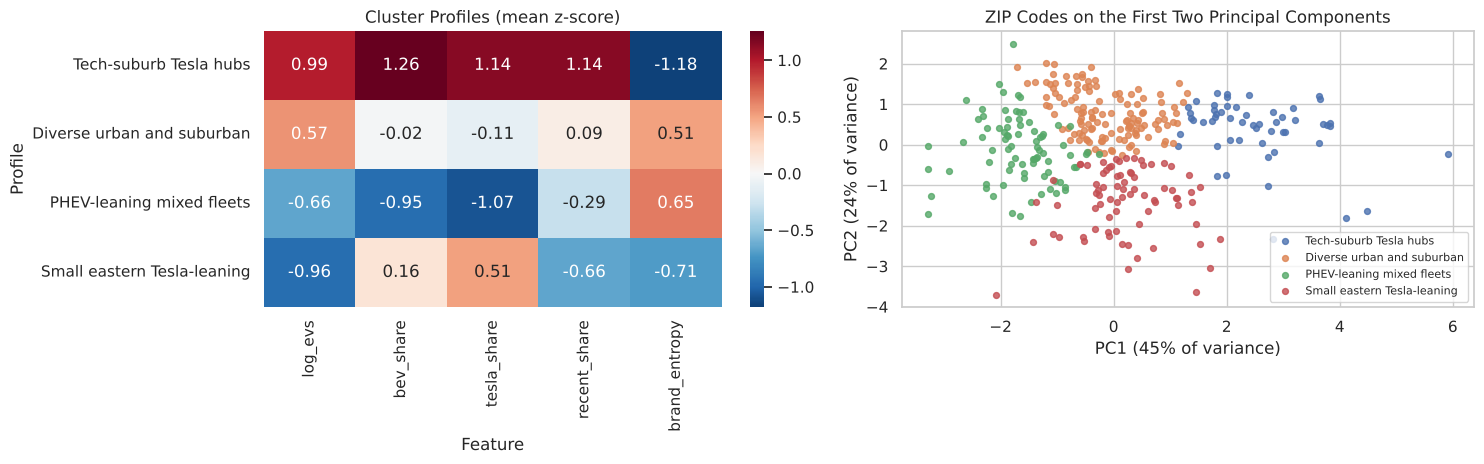

In [8]:
# Profile heatmap (mean z-score of each feature) and PCA map of the ZIP codes
Z = pd.DataFrame(X, columns=features, index=zips.index)
heat = Z.groupby(zips["profile"]).mean().loc[prof.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0])
axes[0].set_title("Cluster Profiles (mean z-score)")
axes[0].set_xlabel("Feature")
axes[0].set_ylabel("Profile")

pcs = PCA(n_components=2).fit(X)
P = pcs.transform(X)
for name in prof.index:
    m = (zips["profile"] == name).values
    axes[1].scatter(P[m, 0], P[m, 1], s=18, alpha=0.8, label=name)
axes[1].set_title("ZIP Codes on the First Two Principal Components")
axes[1].set_xlabel(f"PC1 ({pcs.explained_variance_ratio_[0]:.0%} of variance)")
axes[1].set_ylabel(f"PC2 ({pcs.explained_variance_ratio_[1]:.0%} of variance)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q2_profiles.png", dpi=150)
plt.show()

In [9]:
prof.round(3).to_csv(f"{FIG_DIR}/q2_profiles_python.csv")
zips[["evs", "city", "county", "region", "profile"]].to_csv(f"{FIG_DIR}/q2_zip_profiles_python.csv")

---
# 4. Discussion

The 338 ZIP codes with at least 50 EVs (covering 99.0% of the state's EVs) fall into four profiles:

1. **Tech-suburb Tesla hubs** (54 ZIP codes, 110,724 EVs; Redmond, Bothell, Kirkland, Bellevue,
   Sammamish). The largest fleets (median 1,902 EVs per ZIP), the highest BEV share (86.1%) and Tesla
   share (48.5%), the newest vehicles (67.6% model year 2023+) and the least brand diversity; 91% are in
   the Seattle metro. These are high-income Eastside suburbs with early, premium adoption.
2. **Diverse urban and suburban** (127 ZIP codes, 143,034 EVs; north Seattle, Woodinville, Olympia,
   Camas). Large fleets (median 1,013), an average BEV share (78.2%), fewer Teslas (36.0%) and the widest
   mix of brands: mainstream adoption across many models.
3. **PHEV-leaning mixed fleets** (81 ZIP codes, 26,490 EVs; Tukwila, Bellingham, Renton, Sequim, Port
   Townsend, Vashon). Smaller fleets (median 206), the lowest BEV share (72.4%) and Tesla share (26.3%),
   and high brand diversity; mostly outside the Seattle metro (16% inside).
4. **Small eastern Tesla-leaning** (76 ZIP codes, 15,937 EVs; Pasco, Kennewick, Moses Lake,
   Ellensburg). The smallest fleets (median 146) and the oldest vehicles (55.7% recent), but a fairly high
   BEV share (79.3%) and Tesla share (42.2%); 49% are in eastern Washington. Where adoption is thin, it is
   led by Tesla buyers, perhaps because Tesla's own fast chargers along the I-90 and I-82 corridors make a
   BEV practical.

**What this means.** EV adoption is not one urban–rural gradient. Small markets split into two kinds:
places leaning towards plug-in hybrids and many brands, and eastern towns where a few Tesla buyers
dominate. That matters for charging and incentive planning: the PHEV-leaning areas may respond to more
public charging, while the Tesla-leaning eastern areas may need non-Tesla fast charging so that other
brands become practical. The Tech-suburb hubs are already saturated with Teslas and newer cars.

**Limitations.** The silhouette is modest (0.25), so the groups overlap; ZIP codes are of very
different sizes; the data count registered vehicles, not new sales or vehicles per household, so
adoption *rates* cannot be computed without population data.